In [74]:
import numpy as np #Numpy, various array and statistics functions for handling data
import math #shortcuts for some math symbols, operations in python
import matplotlib.pyplot as plt #Allows plotting the images and displaying
import astropy.units as u #Easy shortcut for attaching units to numbers
from astropy.io import fits #Allows handling of fits files input/output
from photutils.psf import fit_fwhm #Used to fit a gaussian onto stars and measure fwhm
from photutils.profiles import RadialProfile #Used to find the radial profile of the globular cluster and find the half light radius

#from characterize_CCD lab
import os #Functions to interact with the computer system like files
from astropy.wcs import WCS #Allows world coordinate system functions
from astropy.nddata import CCDData #Allows storage of an image including its units
from scipy.stats import scoreatpercentile #How the pixel values are cut to display an image useful to human eyes
import glob #Pattern-matching syntax, we used it in reduction lab for picking out the right fits to combine by their file names.
%matplotlib inline
#The above is a jupyter notebook thing which makes the plots appear right below the cells that call to display
from ccdproc import ImageFileCollection, Combiner, combine #Tools for stacking raw frames might not be needed since our data is already processed
from ccdproc import wcs_project #Reprojects images using WCS onto new coordinate grids when combining dithered images

#from cluster photometry lab
from photutils.detection import DAOStarFinder #Finds stars in an image
from astropy.stats import sigma_clipped_stats #Allows clipping out of stuff by their sigma value and gives stats on data
from photutils.aperture import CircularAperture #Place circular apertures on stars
from astropy.visualization import SqrtStretch #Square-root stretch so faint and bright stars both show, adapt image for human viewing
from astropy.visualization.mpl_normalize import ImageNormalize #Applies a stretch when displaying an image
from astropy.coordinates import SkyCoord #Stores positions in sky and matches the positions to stars in catalogs

# Analysis of M5 (Globular Cluster)

### Importing and Displaying Data for M5

In [75]:
# RA =  15:18:33.22
# Dec = +02:04:51.7

'''
data1, header1 = fits.getdata("cutout_229.6383_2.0808.fits", header=True)
data2, header2 = fits.getdata("cutout_229.6362_2.0609.fits", header=True)
data3, header3 = fits.getdata("cutout_229.6420_2.0902.fits", header=True)
'''

# cutout_229.6420_2.0902.fits has more of the cluster in frame
M5_data, M5_header = fits.getdata("/mnt/e/KUStuff/ASTR596/Capstone/data/cutout_229.6420_2.0902_leesmanm5.fits", header=True)

In [76]:
print(M5_header)

SIMPLE  =                    T / file does conform to FITS standard             BITPIX  =                  -32 / number of bits per data pixel                  NAXIS   =                    3 / number of data axes                            NAXIS1  =                  256 / length of data axis 1                          NAXIS2  =                  256 / length of data axis 2                          NAXIS3  =                    3 / length of data axis 3                          EXTEND  =                    T / FITS dataset may contain extensions            COMMENT   FITS (Flexible Image Transport System) format is defined in 'AstronomyCOMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H SURVEY  = 'LegacySurvey'                                                        VERSION = 'DR11    '                                                            IMAGETYP= 'IMAGE   '           / None                                           BANDS   = 'grz     '                    

In [77]:
#print(header1)

In [78]:
#print(header2)

In [79]:
#print(header3)

In [80]:
'''
# Data has a third axis. I believe that is each band. Bands listed are g, r, and z for 0, 1, and 2, respectively.
M5_data_g = M5_data[0]
M5_data_r = M5_data[1]
M5_data_z = M5_data[2]
'''

'\n# Data has a third axis. I believe that is each band. Bands listed are g, r, and z for 0, 1, and 2, respectively.\nM5_data_g = M5_data[0]\nM5_data_r = M5_data[1]\nM5_data_z = M5_data[2]\n'

In [81]:
# Data has a third axis. I believe that is each band. Bands listed are g, r, and z for 0, 1, and 2, respectively.
M5_data_list = []

M5_band_list = ["g","r"]
for i in M5_data:
    M5_data_list.append(i)

In [82]:
def imdisplay(image, v1perc=10, v2perc=95, logscale=True):
    '''
    display an image 
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    fig,ax = plt.subplots(figsize=(6,6))
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile
    v1 = scoreatpercentile(nimage,v1perc)
    v2 = scoreatpercentile(nimage,v2perc)
    # display using imshow
    #
    # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
    # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
    #
    # vmin and vmax set the min and max pixel values that
    # will be mapped to the extremes of the colormap
    print(v1,v2)
    if (logscale):
        im = ax.imshow(nimage,cmap='gray_r',aspect='equal',norm=colors.LogNorm(vmin=v1,vmax=v2),origin='lower')
    else:
        im = ax.imshow(nimage,cmap='gray_r',aspect='equal',vmin=v1,vmax=v2,origin='lower')
        
    cbar = fig.colorbar(im, ax=ax, fraction=0.04)
    cbar.ax.set_ylabel('counts')
    return fig,ax

-0.0012777181982528418 10.8770707082749
-0.0017138301453087478 15.44058883667001


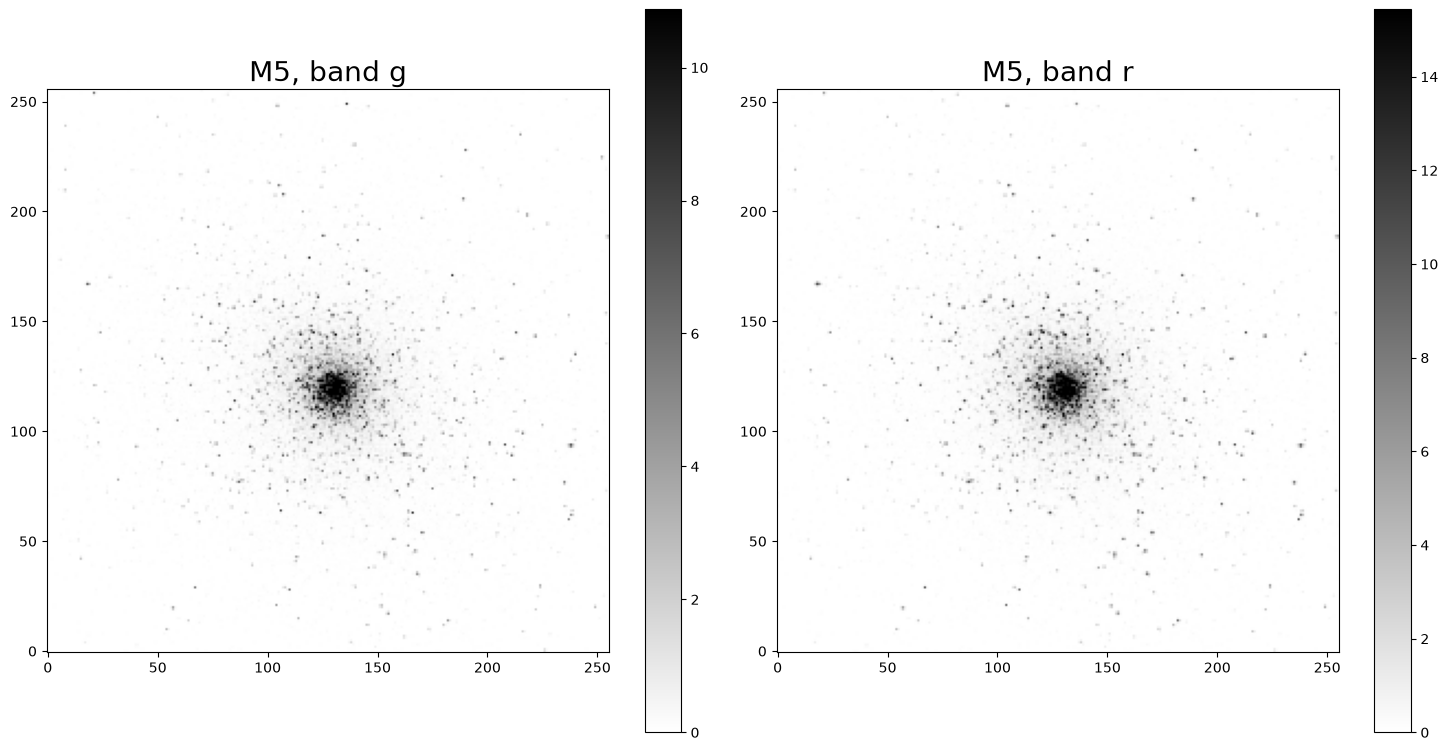

In [83]:
fig1 = plt.figure(1, figsize=(15,15))

for i in range(len(M5_band_list)):
    ax = plt.subplot(2,2,i+1)
    nimage = np.array(M5_data_list[i])
    # Determine the pixel values at the 1st and 99.9th percentile (basically all of them). These will be the min and max of the colormap.
    v1 = scoreatpercentile(nimage, 1.0)
    v2 = scoreatpercentile(nimage, 99.9)
    print(v1, v2)
    plt.imshow(M5_data_list[i], cmap="gray_r", origin="lower", vmin=v1, vmax=v2)
    plt.title(f"M5, band {M5_band_list[i]}", fontsize=20)
    plt.colorbar()
plt.tight_layout()

# Photometry of M5

All images already have matching WCS.

To find the outer stars, first find the center of the cluster, then create increasingly large circles centered on that center and calculate the flux from within it to determine the cluster's profile.
From there, we can determine which radiative profile represents the outer stars.

### Removing Background
The corners can be used as an approximation of background. By subtracting that from the pixels in the image, we can remove the background.

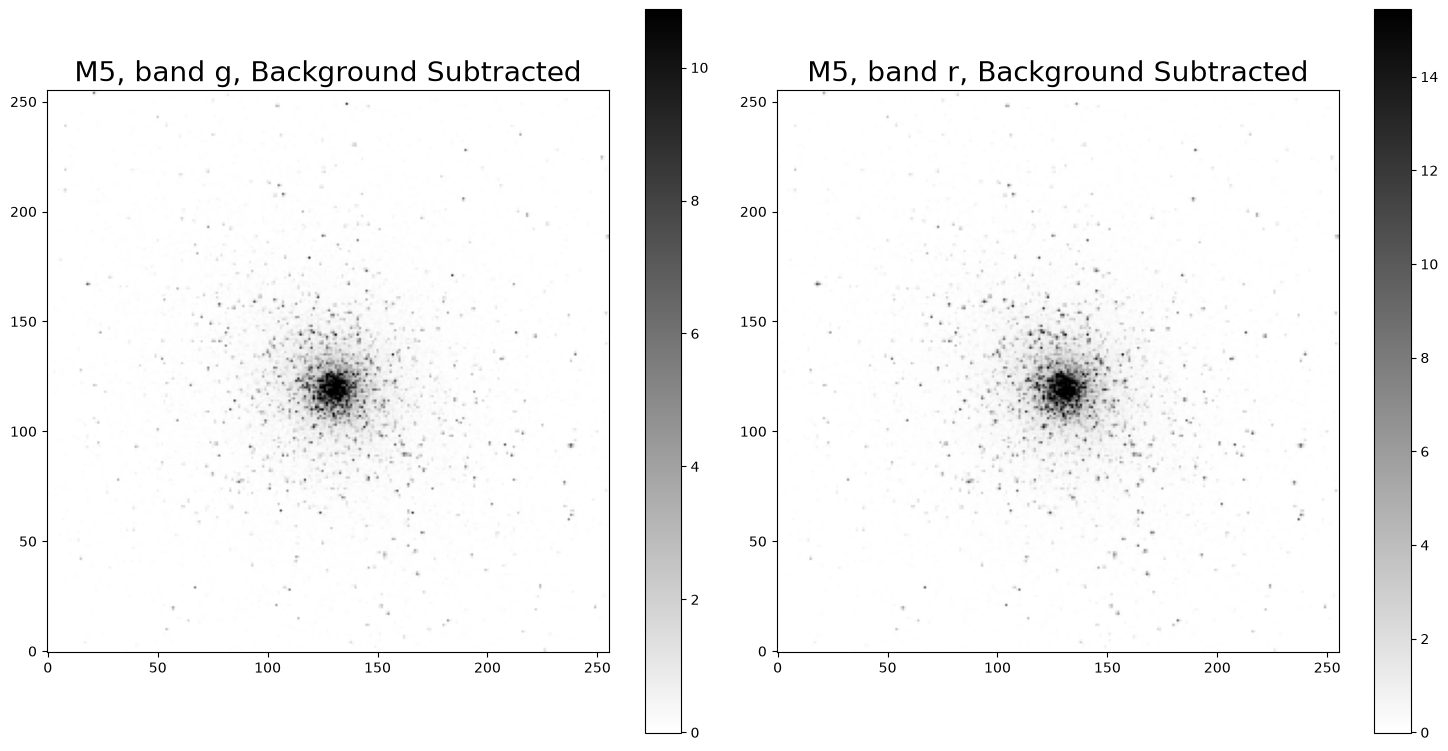

In [84]:
# Plotting the images with the squares for background subtraction
# Corner squares should be 40x40
M5_data_list_bsub = []
fig2 = plt.figure(1, figsize=(15,15))

for i in range(len(M5_band_list)):
    # Squares should be 40x40
    M5_data_bkg = M5_data_list[i]
    UpperLeftSquare = M5_data_bkg[:40, :40]
    LowerRightSquare = M5_data_bkg[-40:, -40:]
    UpperRightSquare = M5_data_bkg[:40, -40:]
    LowerLeftSquare = M5_data_bkg[-40:, :40]
    M5_bkg = []
    M5_bkg.append(UpperLeftSquare)
    M5_bkg.append(LowerRightSquare)
    M5_bkg.append(UpperRightSquare)
    M5_bkg.append(LowerLeftSquare)
    # Find the median of the values in the background squares
    M5_bkg_med = np.median(M5_bkg)
    # Subtract that median from each of the pixels in the images
    M5_data_bsub = M5_data_bkg - M5_bkg_med
    M5_data_list_bsub.append(M5_data_bsub)
    
    nimage_bsub = np.array(M5_data_bsub)
    # Determine the pixel values at the 1st and 99.9th percentile (basically all of them). These will be the min and max of the colormap.
    v1 = scoreatpercentile(nimage_bsub, 1.0)
    v2 = scoreatpercentile(nimage_bsub, 99.9)
    
    ax = plt.subplot(2,2,i+1)
    plt.imshow(M5_data_bsub, cmap="gray_r", origin="lower", vmin=v1, vmax=v2)
    plt.title(f"M5, band {M5_band_list[i]}, Background Subtracted", fontsize=20)
    plt.colorbar()
plt.tight_layout()

### Finding The Outer Stars

Find halflight radius

Text(0.5, 0, 'Radius')

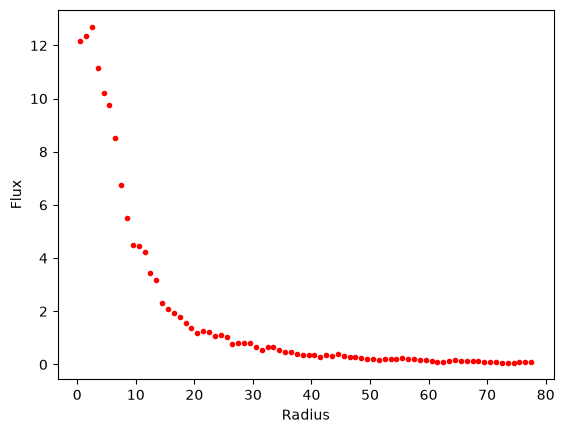

In [85]:
# Initial guesses of center and SemiMajor axis in pixels; SemiMajor axis = SemiMinor axis for the shape chosen
# [129.8370pix, 119.3202pix], [22.0710pix, 20.3900pix]
M5_xcen = 129.1643
M5_ycen = 118.9031
M5_smaj = 78.2194
# Same for all bands

M5_data_g_bsub = M5_data_list_bsub[0]
M5_data_r_bsub = M5_data_list_bsub[1]

rp = RadialProfile(data=M5_data_g_bsub, xycen=(M5_xcen, M5_ycen), radii=np.arange(0,78.2194))
plt.errorbar(rp.radius, rp.profile, fmt='r.')
plt.ylabel("Flux")
plt.xlabel("Radius")


In [86]:
print(rp.profile[5])
print(rp.radius[5])

9.770441065377028
5.5


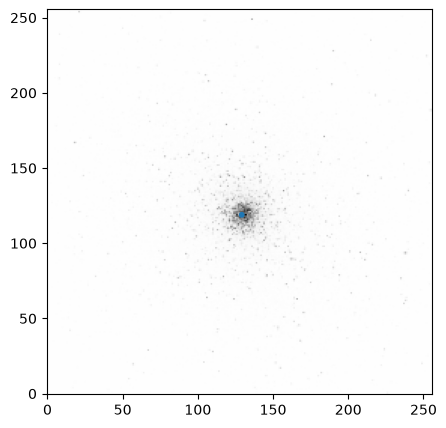

In [87]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(M5_data_g_bsub, origin='lower', cmap='Grays')
for i in range(1):
    rp.apertures[i].plot(ax=ax, color=f'C{i}', lw=2)

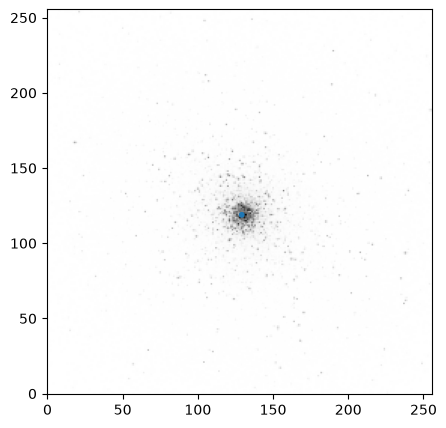

In [88]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(M5_data_r_bsub, origin='lower', cmap='Grays')
for i in range(1):
    rp.apertures[i].plot(ax=ax, color=f'C{i}', lw=2)

### Masking the stars inside the center

In [89]:
# Masking Pixels falling within the half light radius
half_light_radius = rp.radius[0] # Pixels; can be varried to include more of the cluster

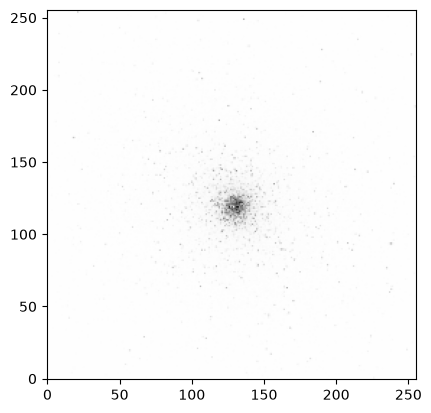

In [90]:


# Loop checks if a given pixel is within the half light radius and adds them to an array if they are.
M5_data_g_bsub_masked = M5_data_list_bsub[0]
for i in np.arange(0,M5_header["NAXIS1"]):
    for j in np.arange(0,M5_header["NAXIS2"]):
        r = math.sqrt(((i-M5_xcen)**2)+((j-M5_ycen)**2))    # radial distance from center calculation
        if r <= half_light_radius:
            M5_data_g_bsub_masked[j][i] = np.nan
plt.imshow(M5_data_g_bsub_masked, cmap='Grays', origin="lower")

#Save the image as a new fits file
fits.writeto('M5G.fits', M5_data_g_bsub_masked, overwrite=True, header=M5_header)

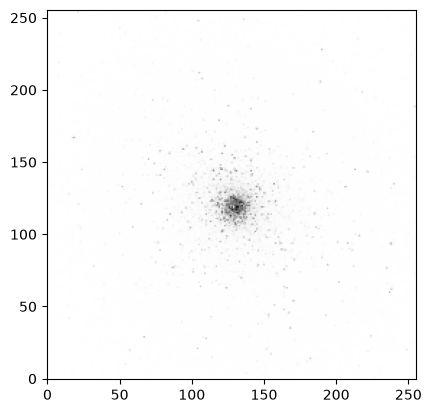

In [91]:
# Same thing for the r band
M5_data_r_bsub_masked = M5_data_list_bsub[1]
for i in np.arange(0,M5_header["NAXIS1"]):
    for j in np.arange(0,M5_header["NAXIS2"]):
        r = math.sqrt(((i-M5_xcen)**2)+((j-M5_ycen)**2))    # radial distance from center calculation
        if r <= half_light_radius:
            M5_data_r_bsub_masked[j][i] = np.nan
plt.imshow(M5_data_r_bsub_masked, cmap='Grays', origin="lower")

#Save the image as a new fits file
fits.writeto('M5R.fits', M5_data_r_bsub_masked, overwrite=True, header=M5_header)

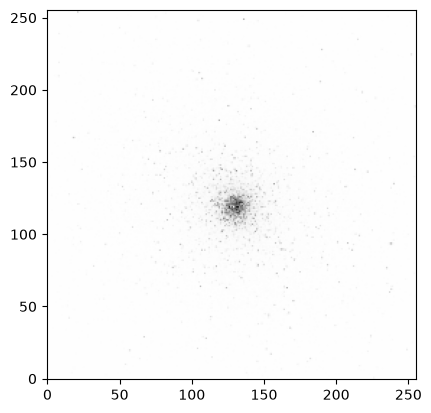

In [92]:
# Testing the new fits files
plt.imshow(fits.getdata('M5G.fits'), cmap='Grays', origin="lower")

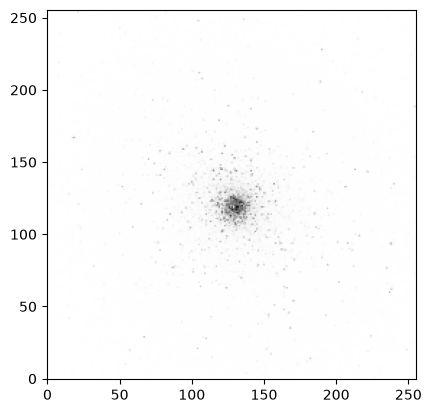

In [93]:
plt.imshow(fits.getdata('M5R.fits'), cmap='Grays', origin="lower")

## PSF Measurement
Fits FWHM to the outer stars of the cluster 

### Sigma Clipping

In [94]:
# Sigma Clip each image to further remove background

# Obtain mean, median, std dev
for i in range(len(M5_band_list)):
    M5_mean, M5_median, M5_stdev = sigma_clipped_stats(M5_data_list[i], sigma=3.0)
    print(f"{M5_band_list[i]} Mean", M5_mean)
    print(f"{M5_band_list[i]} Median", M5_median)
    print(f"{M5_band_list[i]} Std Dev", M5_stdev)

g Mean 0.01772707
g Median 0.005419096
g Std Dev 0.026131192
r Mean 0.028951237
r Median 0.010552436
r Std Dev 0.040230278


In [95]:
# PSF measurement function from lab
from astropy.io import fits
from photutils.psf import fit_fwhm

def calc_fwhm(imagefilename, xyposlist):
    '''
    This function takes as input an image file name and a list of star pixel coordinates 
    and prints the FWHM for each star.  

    Stars should be bright, unsaturated, and isolated.

    INPUTS: 
    imagefilename: a string containing the image file name

    xyposlist: a list of x and y coordinates of the form [(x1,y1), (x2,y2)]
    This can contain an arbitrary number of stars.

    OUTPUT:
    fwhmlist: a list of FWHM
    '''
    image = fits.getdata(imagefilename)
    
    #use the photutils.psf.fit_fwhm function to fit a 2D PSF to the stars.
    fwhm = fit_fwhm(
        image,
        xypos=xyposlist,
        fwhm=4.0,        # initial guess from lab
        fit_shape=21
    )
    print(f'The FWHM of the stars in {imagefilename} in pixels are {fwhm}')
    return(fwhm)

In [96]:
# 5 stars in M5 in pixel coordinates
M5_stars = [(184.0285, 170.9012), (119.0643, 178.9181), (116.9973, 77.7644), (106.0191, 63.8749), (124.0330, 62.8438)]

In [97]:
# FWHM of each of the stars
M5_fwhmlist_g = calc_fwhm('M5G.fits', M5_stars)
M5_fwhmlist_r = calc_fwhm('M5R.fits', M5_stars)

# Average FWHM
M5_fwhm_g = np.mean(M5_fwhmlist_g)
M5_fwhm_r = np.mean(M5_fwhmlist_r)

The FWHM of the stars in M5G.fits in pixels are [0.5143377  0.68096822 0.57113918 0.36625711 0.77786807]
The FWHM of the stars in M5R.fits in pixels are [0.77869986 0.78182155 0.85723971 0.72655506 1.07312389]


In [98]:
M5_data_g, M5_header_g = fits.getdata('M5G.fits', header=True)
M5_data_r, M5_header_r = fits.getdata('M5R.fits', header=True)

In [99]:
# Obtain mean, median, std dev
M5_mean_g, M5_median_g, M5_stdev_g = sigma_clipped_stats(M5_data_g, sigma=3.0)
M5_mean_r, M5_median_r, M5_stdev_r = sigma_clipped_stats(M5_data_r, sigma=3.0)

Text(0.5, 1.0, 'g-band detected sources')

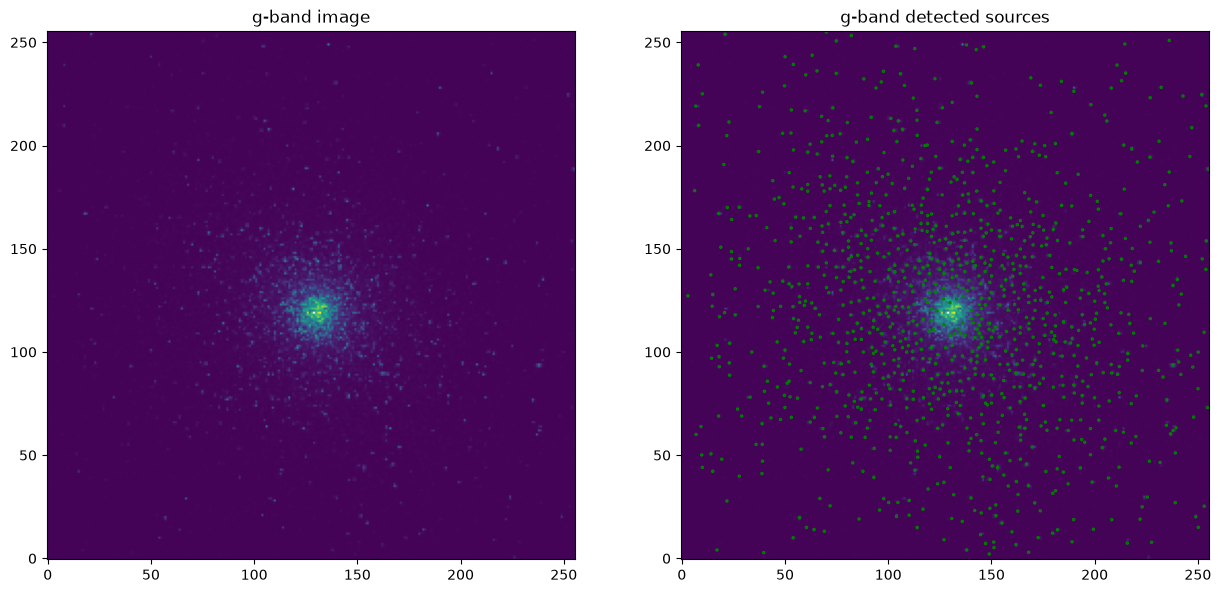

In [100]:
# set up daofind, with info about our image fwhm and the detection threshold
#*****************************************
daofind = DAOStarFinder(fwhm=M5_fwhm_g, threshold=6.0*M5_stdev_g) #was 4, switched to 10.0 to optimize detection from graph of next code cell.

# detect sources, using the image - median, which subtracts the sky level from the image, 
# assuming a sky that is constant across the image
sources_g = daofind(M5_data_g - M5_median_g)

M5_wcs_g = WCS(M5_header_g)
M5_ra_g,M5_dec_g = M5_wcs_g.wcs_pix2world(sources_g['xcentroid'],sources_g['ycentroid'],0)

# plot images and the sources.  using the subplot command we can plot figures side by side
plt.figure(figsize=(15,10))
# select the left plot
plt.subplot(1,2,1)
plt.imshow(M5_data_g, origin='lower')
plt.title('g-band image')

# plot r-band image with the positions of the sources overlaid
# select the right plot
plt.subplot(1,2,2)

# Create a list of positions of all the stars, as determined by the DAOStarFinder above.  
# The transpose command puts the positions into the correct format
positions = np.transpose((sources_g['xcentroid'], sources_g['ycentroid']))
# creates a set of circular apertures (r=1 chosen since stars are small and image is dense)
apertures = CircularAperture(positions, r=0.5)
plt.imshow(M5_data_g, origin='lower')
# plot the apertures. the ';' at the end suppresses some messy output
apertures.plot(color='green', lw=1.0, alpha=1.0);
plt.title('g-band detected sources')

Text(0.5, 1.0, 'g-band')

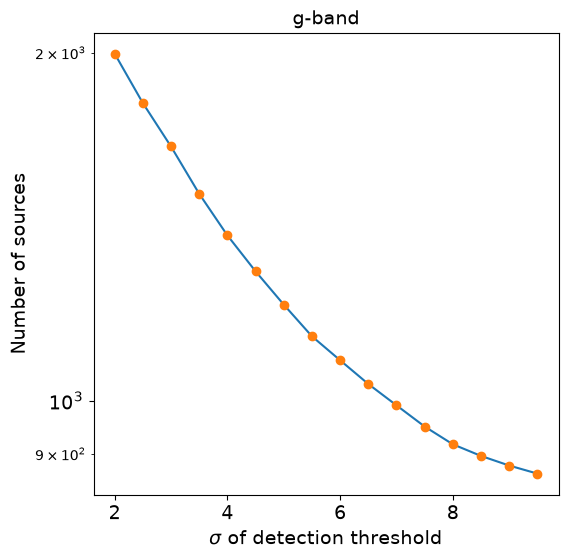

In [101]:
# This makes a plot of the number of sources for different detection thresholds for the g-band
# set up an array of thresholds
thresharr = np.arange(2.,10.,0.5)

# initialize an array that will hold the number of sources detected at each threshold
nsources_g = np.zeros(len(thresharr))

# loop through the thresholds to find how many sources are detected at each threshold
for ithresh,thresh in enumerate(thresharr):
    daofind_tmp = DAOStarFinder(fwhm=M5_fwhm_g, threshold=thresh*M5_stdev_g)
    sources_gtmp = daofind_tmp(M5_data_g - M5_median_g)
    nsources_g[ithresh] = len(sources_gtmp)

# plot the number of sources at each threshold
fig,ax = plt.subplots(figsize=(6,6))
ax.plot(thresharr,nsources_g)
ax.plot(thresharr,nsources_g, 'o')
ax.set_yscale('log')
ax.set_ylabel('Number of sources', fontsize=14)
ax.set_xlabel(r'$\sigma$ of detection threshold', fontsize=14)
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)
ax.set_title('g-band', fontsize=14)

Text(0.5, 1.0, 'r-band detected sources')

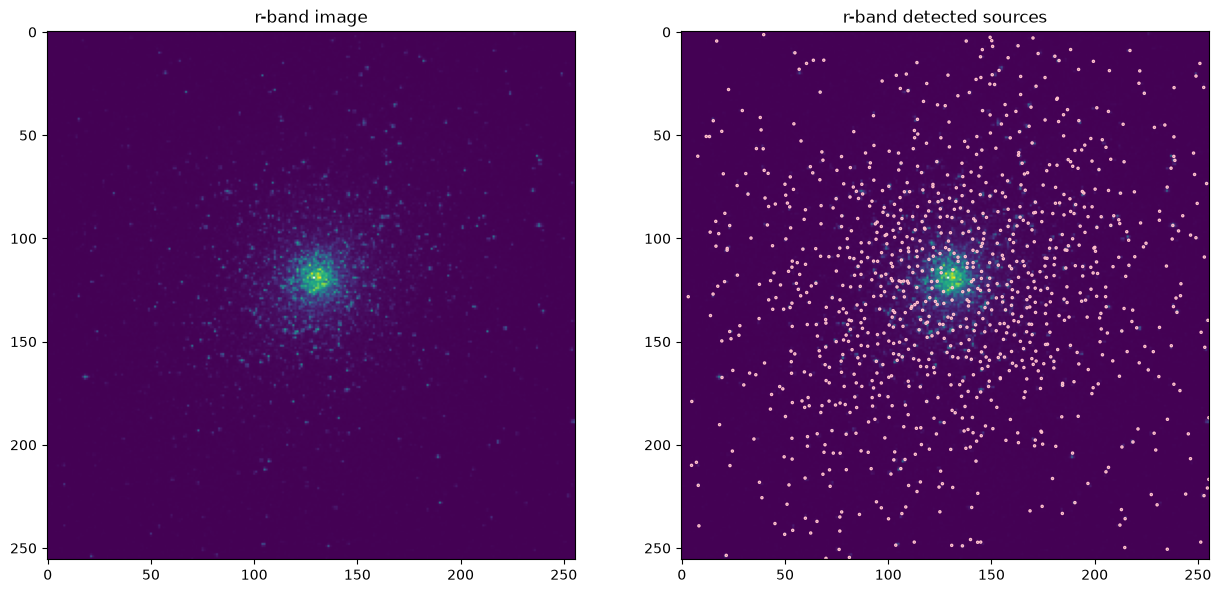

In [102]:
# set up daofind, with info about our image fwhm and the detection threshold
#*****************************************
daofind = DAOStarFinder(fwhm=M5_fwhm_r, threshold=6.0*M5_stdev_r) #was 4, switched to 10.0 to optimize detection from graph of next code cell.

# detect sources, using the image - median, which subtracts the sky level from the image, 
# assuming a sky that is constant across the image
sources_r = daofind(M5_data_r - M5_median_r)

M5_wcs_r = WCS(M5_header_r)
M5_ra_r,M5_dec_r = M5_wcs_r.wcs_pix2world(sources_r['xcentroid'],sources_r['ycentroid'],0)

# plot images and the sources.  using the subplot command we can plot figures side by side
plt.figure(figsize=(15,10))
# select the left plot
plt.subplot(1,2,1)
plt.imshow(M5_data_r)
plt.title('r-band image')

# plot r-band image with the positions of the sources overlaid
# select the right plot
plt.subplot(1,2,2)

# Create a list of positions of all the stars, as determined by the DAOStarFinder above.  
# The transpose command puts the positions into the correct format
positions = np.transpose((sources_r['xcentroid'], sources_r['ycentroid']))
# creates a set of circular apertures (r=1 chosen since stars are small and image is dense)
apertures = CircularAperture(positions, r=0.5)
plt.imshow(M5_data_r)
# plot the apertures. the ';' at the end suppresses some messy output
apertures.plot(color='pink', lw=1.0, alpha=1.0);
plt.title('r-band detected sources')

Text(0.5, 1.0, 'r-band')

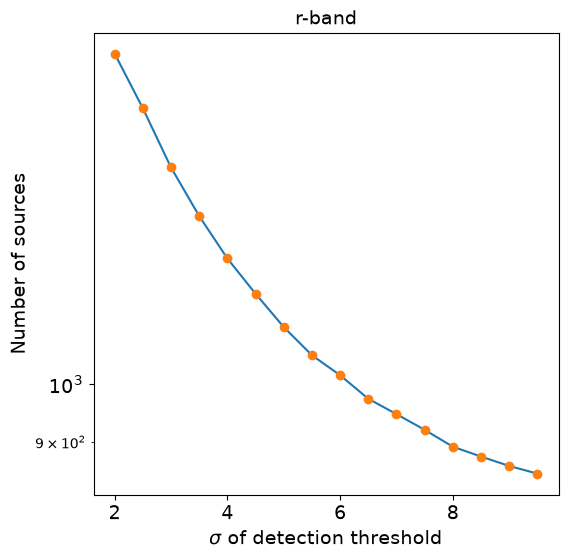

In [103]:
# This makes a plot of the number of sources for different detection thresholds for the r-band
# set up an array of thresholds
thresharr = np.arange(2.,10.,0.5)

# initialize an array that will hold the number of sources detected at each threshold
nsources_r = np.zeros(len(thresharr))

# loop through the thresholds to find how many sources are detected at each threshold
for ithresh,thresh in enumerate(thresharr):
    daofind_tmp = DAOStarFinder(fwhm=M5_fwhm_r, threshold=thresh*M5_stdev_r)
    sources_rtmp = daofind_tmp(M5_data_r - M5_median_r)
    nsources_r[ithresh] = len(sources_rtmp)

# plot the number of sources at each threshold
fig,ax = plt.subplots(figsize=(6,6))
ax.plot(thresharr,nsources_r)
ax.plot(thresharr,nsources_r, 'o')
ax.set_yscale('log')
ax.set_ylabel('Number of sources', fontsize=14)
ax.set_xlabel(r'$\sigma$ of detection threshold', fontsize=14)
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)
ax.set_title('r-band', fontsize=14)

The images have had their background removed and stars sigma clipped; the stars must now be matched.

### Matching Stars in the Bands

In [104]:
print(sources_g)
print(sources_r)

 id      xcentroid          ycentroid      ...     mag          daofind_mag     
---- ------------------ ------------------ ... ------------ --------------------
   1 148.95812728277846  2.117002019385304 ...   0.19001153  -1.3316742660200105
   2 39.665477351311736 2.7626534631924513 ...   0.30032012 -0.37881236797151135
   3 167.97503413728055  2.929188804732311 ...    0.8927276 -0.12283822890891193
   4 17.041476234826987  4.060362143684967 ...   0.09491271  -1.6020900385851546
   5 138.00876158442475  4.054098102348864 ...   -1.1086806  -2.3697909611562697
   6 151.23010490577073  5.190542029490259 ...    0.4298119 -0.19548493008052756
   7 147.17450149958674  7.229014995967212 ...   0.55640393 -0.44404374448490574
   8 161.85798323371603  6.648175544153606 ...   -1.1063015   -2.075841578522116
   9  151.1035418884938  7.892761240079318 ... -0.017389584   -1.248399227249551
  10  189.0644229361539  8.022519978556366 ...   0.34871745  -0.1843027565931673
 ...                ...     

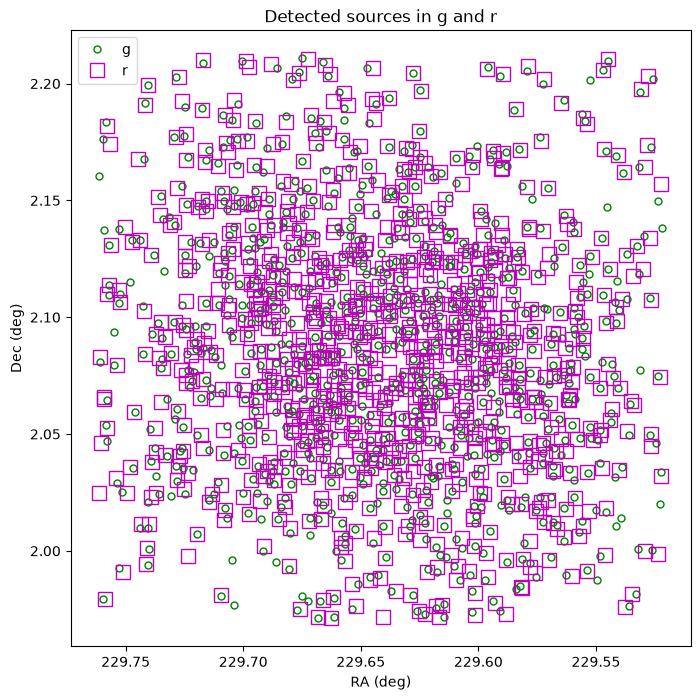

In [105]:
#************************* took this from labs
# make a plot of the RA and DEC of the sources in the g and r images

# boolean flags for good positions (> 20 pixels from every edge) in the g and r-band images
ny, nx = M5_data_g.shape
noedgeflag_g = ((sources_g['xcentroid'] > 20) & (sources_g['xcentroid'] < nx-20) &
                (sources_g['ycentroid'] > 20) & (sources_g['ycentroid'] < ny-20))
noedgeflag_r = ((sources_r['xcentroid'] > 20) & (sources_r['xcentroid'] < nx-20) &
                (sources_r['ycentroid'] > 20) & (sources_r['ycentroid'] < ny-20))

# open a figure
plt.figure(figsize=(8,8))

# plot the positions of the g sources
plt.plot(M5_ra_g[noedgeflag_g], M5_dec_g[noedgeflag_g],'g.',mfc='None',markersize=10,label='g')

# plot the positions of the r sources
plt.plot(M5_ra_r[noedgeflag_r], M5_dec_r[noedgeflag_r],'ms',mfc='None',markersize=10,label='r')

# add a legend
plt.legend()

# label your axes
plt.xlabel('RA (deg)')
plt.ylabel('Dec (deg)')
plt.gca().invert_xaxis()   # RA increases to the left on the sky
plt.title('Detected sources in g and r')

# save your plot
plt.savefig('M67_g_r_positions.png')

In [106]:
# this creates a SkyCoord object containing the g and r catalogs
g_catalog = SkyCoord(ra=M5_ra_g*u.degree, dec=M5_dec_g*u.degree)
r_catalog = SkyCoord(ra=M5_ra_r*u.degree, dec=M5_dec_r*u.degree)

# this matches the two catalogs and outputs an array of indices, idx, that when passed to r_catalog
# gives the ids of the matched sources for each source in g_catalog.
idx, d2d, d3d = g_catalog.match_to_catalog_sky(r_catalog)

# Consider regions the same source when they are within 0.0011111111 deg of each other (Found by sqrt((0.00111111111111)**2+(0)**2)
matchflag = d2d < 0.0011111111*u.deg
gmag = sources_g['mag'][matchflag]
rmag = sources_r['mag'][idx[matchflag]]

# also keep the sky position of each matched star (taken from the g catalog) for the radial analysis later
ra_match  = M5_ra_g[matchflag]
dec_match = M5_dec_g[matchflag]

print('number of matched stars:', matchflag.sum())
print(gmag, rmag)

number of matched stars: 400
    mag    
-----------
 0.19001153
 0.09491271
 -1.1086806
 0.34871745
 -1.4444427
 -1.0881927
 -1.4943177
  0.6411997
-0.92935395
 -2.3348444
        ...
 -1.6812174
  0.7327111
-0.87781596
 -1.0934017
 0.02709192
 0.87164944
  -2.045412
  1.2447475
 -2.1425266
   1.291928
Length = 400 rows     mag     
------------
 -0.47461456
   -0.254572
  -1.7859557
-0.034075394
  -1.8786356
  -1.8273562
  -1.5217823
  0.22706813
  -1.5178953
  -3.1196938
         ...
  -1.6835024
  0.18722968
  -0.5480872
  -1.5610094
 -0.04379243
-0.002770532
  -2.8387733
  0.94398713
  -2.2932122
  0.80204314
Length = 400 rows


In [107]:
# Calibration
# 22.5
gmag_cal = gmag + 22.5
rmag_cal = rmag + 22.5

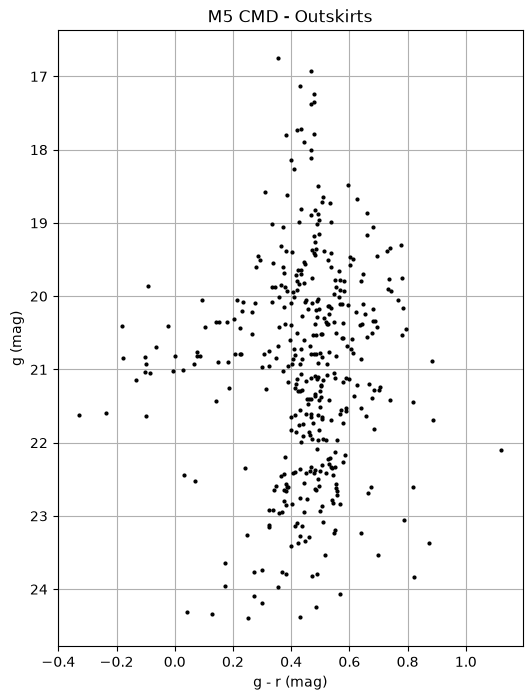

In [108]:
# CMD: g flux vs g - r color (lab used B-V)
plt.figure(figsize=(6,8))
plt.plot(gmag_cal - rmag_cal, gmag_cal, 'k.', markersize=4)
plt.xlabel('g - r (mag)')
plt.ylabel('g (mag)')
plt.title('M5 CMD - Outskirts')

plt.gca().invert_yaxis()   # brighter stars (smaller magnitudes) at the top
plt.grid(True)
plt.savefig('M5_CMD_outskirts.png')

M5 has a suprisingly few number of red stars. Globular clusters tend to be older, so this few red stars is suprising. I expected to see a branch analogous to the red giant branch in the plot, but I do not. This likely has something to do with failing to include some stars. 

In [37]:
"""
We reused variable names so store the ones needed later from M5 here:
"""

M5_cmd_color = np.array(gmag_cal - rmag_cal)
M5_cmd_g = np.array(gmag_cal)

In [38]:
import numpy as np #Numpy, various array and statistics functions for handling data
import math #shortcuts for some math symbols, operations in python
import matplotlib.pyplot as plt #Allows plotting the images and displaying
import astropy.units as u #Easy shortcut for attaching units to numbers
from astropy.io import fits #Allows handling of fits files input/output
from photutils.psf import fit_fwhm #Used to fit a gaussian onto stars and measure fwhm

from matplotlib.patches import Rectangle

#from characterize_CCD lab
import os #Functions to interact with the computer system like files
from astropy.wcs import WCS #Allows world coordinate system functions
from astropy.nddata import CCDData #Allows storage of an image including its units
from scipy.stats import scoreatpercentile #How the pixel values are cut to display an image useful to human eyes
import glob #Pattern-matching syntax, we used it in reduction lab for picking out the right fits to combine by their file names.
%matplotlib inline
#The above is a jupyter notebook thing which makes the plots appear right below the cells that call to display
from ccdproc import ImageFileCollection, Combiner, combine #Tools for stacking raw frames might not be needed since our data is already processed
from ccdproc import wcs_project #Reprojects images using WCS onto new coordinate grids when combining dithered images

#from cluster photometry lab
from photutils.detection import DAOStarFinder #Finds stars in an image
from astropy.stats import sigma_clipped_stats #Allows clipping out of stuff by their sigma value and gives stats on data
from photutils.aperture import CircularAperture #Place circular apertures on stars
from astropy.visualization import SqrtStretch #Square-root stretch so faint and bright stars both show, adapt image for human viewing
from astropy.visualization.mpl_normalize import ImageNormalize #Applies a stretch when displaying an image
from astropy.coordinates import SkyCoord #Stores positions in sky and matches the positions to stars in catalogs


# M67 (Open Cluster) Analysis
Builds CMD of g-r using a cutout of 3000x3000 pixels at .5 arcsec/pixel (download constraints).
Detects stars in g and r by first finding FWHM to use, then makes CMD of the entire cluster, and one of just the outskirts.

In [39]:
alex_data_dir= '/mnt/e/KUStuff/ASTR596/Capstone/data'
M67_fit='/mnt/e/KUStuff/ASTR596/Capstone/data/cutout_132.8471_11.8172big.fits'
#the fits is a 3000x3000 pixel area with 3 bands. .5 arcsec/pixel resolution for size reasons.

m67_center=SkyCoord('08h51m23.3s', '+11d49m02s')
zeropoint=22.5 #zeropoint of ls dr11

In [40]:
def imdisplay(image, v1perc=10, v2perc=95):
    #Image display from labs without big comments
    nimage = np.array(image)  # make sure image is an np array
    v1 = scoreatpercentile(nimage,v1perc) # determine the pixel values for percentiles to scale
    v2 = scoreatpercentile(nimage,v2perc)
    plt.imshow(nimage, cmap='gray_r', vmin=v1, vmax=v2, origin='lower') #origin flips the image
    plt.colorbar(fraction=.08) #all same as lab

def add_stars(xstars, ystars, radius=20, color='r', ax=None): #Add circles around stars
    if ax is None:
        ax = plt.gca()
    for x, y in zip(xstars, ystars):
        c = plt.Circle((x, y), radius, color=color, fill=False)
        ax.add_artist(c)

# Loading Data
Reads the 3-band image and gets pixel scale, specifies shape of fits.

Also turns the 3-band image into 3 different images based on band to be more similar to familiar lab

In [41]:
os.chdir(alex_data_dir)

# Load the data from headers and image into variables.
cube, cube_header = fits.getdata('cutout_132.8471_11.8172big.fits', header=True)
print('fits shape (band, y, x):', cube.shape)

# pixel scale in arcsec/pixel, from the CD matrix in the header (degrees/pixel)
pixscale = abs(cube_header['CD2_2'])*3600.
print('pixel scale (arcsec/pix):', pixscale)

fits shape (band, y, x): (3, 3000, 3000)
pixel scale (arcsec/pix): 0.5000000000000004


In [42]:
# Split the cube into 2d files by band to be closer to lab
# build the WCS conversion using the header values
wcs2d = WCS(cube_header, naxis=2)

for i, band in enumerate(['g','r','z']): #go through bands and replace 
    img = cube[i].astype('float32') #Store new images values as float32 data type
    hdr = wcs2d.to_header() #From WCS, write the wcs details to the new image headers
    hdr['BAND'] = band #write band and zero point
    hdr['PHOTZP'] = 22.5
    fits.writeto(f'M67{band}.fits', img, header=hdr, overwrite=True) #write the new images
    print('wrote', f'M67{band}.fits')

wrote M67g.fits
wrote M67r.fits
wrote M67z.fits


# Display the image for each band

Check that the data is comparable and nothing egregiously wrong with the data.

Text(0, 0.5, 'y (pixels)')

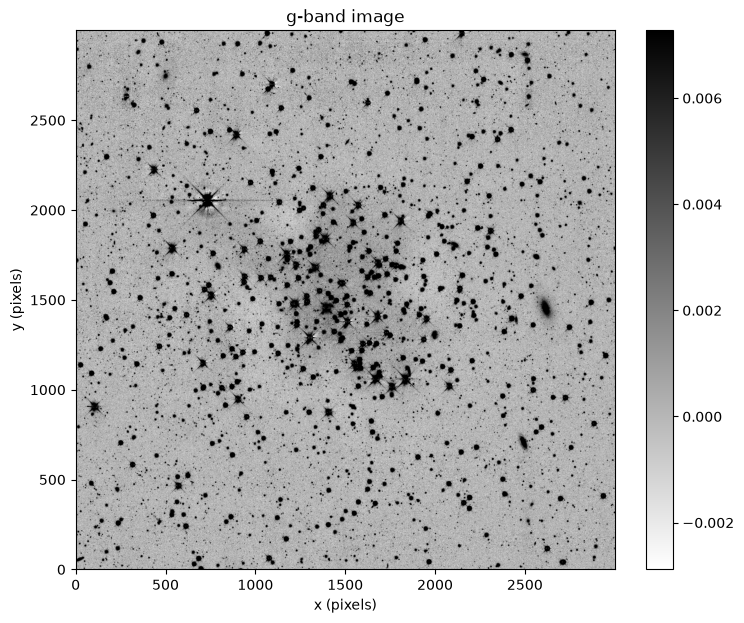

In [43]:
# make the figure
plt.figure(figsize=(8,7))
# read in the data and header
data,header = fits.getdata('M67g.fits', header=True)

imdisplay(data) #Display g band
plt.title("g-band image")
plt.xlabel('x (pixels)'); plt.ylabel('y (pixels)')

Text(0, 0.5, 'y (pixels)')

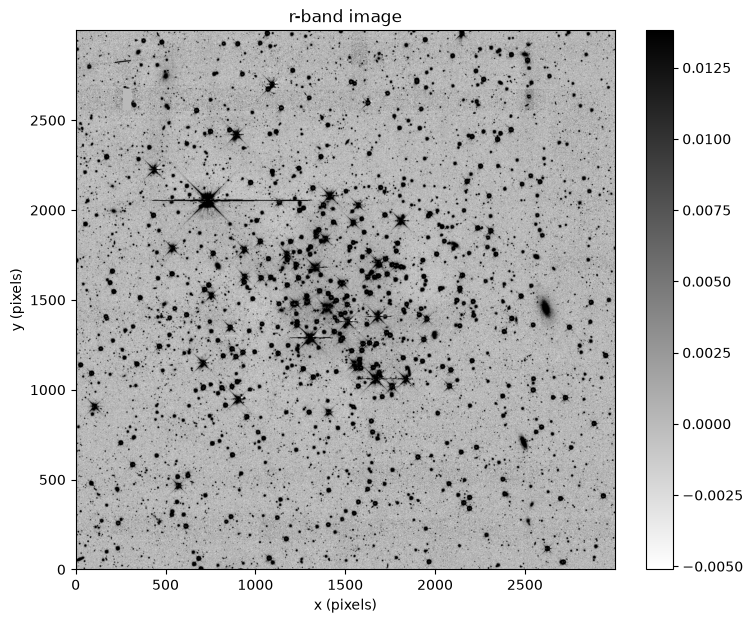

In [44]:
#same as previous cell but for r
plt.figure(figsize=(8,7))
data,header = fits.getdata('M67r.fits', header=True)
imdisplay(data)
plt.title("r-band image")
plt.xlabel('x (pixels)'); plt.ylabel('y (pixels)')

Text(0, 0.5, 'y (pixels)')

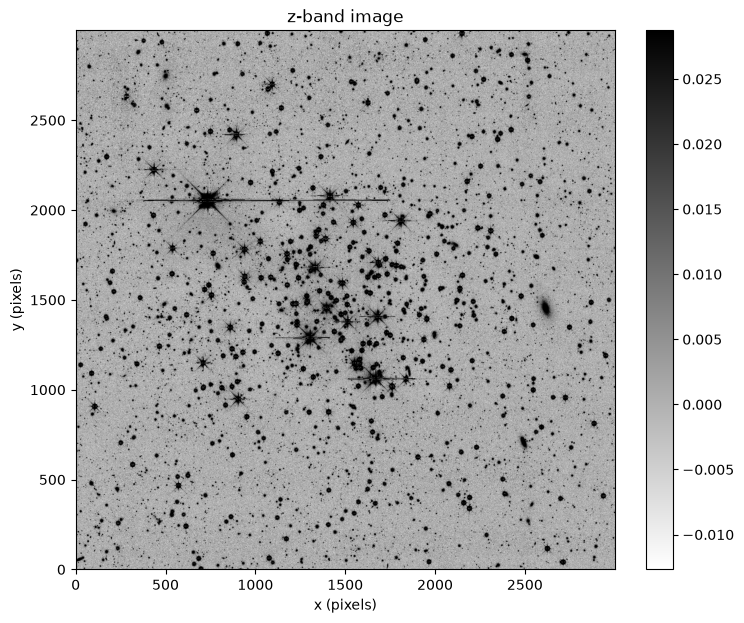

In [45]:
#same as previous cell but for z
plt.figure(figsize=(8,7))
data,header = fits.getdata('M67z.fits', header=True)
imdisplay(data)
plt.title("z-band image")
plt.xlabel('x (pixels)'); plt.ylabel('y (pixels)')

In [46]:
# Since the images don't get averaged like in lab get some statistics and noise data for thought.
for band in ['g','r','z']:
    data_m67 = fits.getdata(f'M67{band}.fits')
    mean, median, stdev = sigma_clipped_stats(data_m67, sigma=3.0)   # ignore pixels > 3 sigma (stars)
    print(f'{band}-band: mean={mean:.4f}  median={median:.4f}  noise std={stdev:.4f} nanomaggies')

g-band: mean=0.0003  median=0.0002  noise std=0.0026 nanomaggies
r-band: mean=0.0005  median=0.0004  noise std=0.0045 nanomaggies
z-band: mean=0.0011  median=0.0009  noise std=0.0110 nanomaggies


z isn't used for analysis but g and r are. These stats aren't used directly (another version is used later when fitting sources with FWHM and such.)
Thought it might be good to keep regardless.

# PSF Measurement
Fits a FWHM to stars which were manually chosen to get an estimate of a good FWHM to use during large-scale detection.


In [47]:
# PSF measurement function from lab
from astropy.io import fits
from photutils.psf import fit_fwhm

def calc_fwhm(imagefilename, xyposlist):
    '''
    This function takes as input an image file name and a list of star pixel coordinates 
    and prints the FWHM for each star.  

    Stars should be bright, unsaturated, and isolated.

    INPUTS: 
    imagefilename: a string containing the image file name

    xyposlist: a list of x and y coordinates of the form [(x1,y1), (x2,y2)]
    This can contain an arbitrary number of stars.

    OUTPUT:
    fwhmlist: a list of FWHM
    '''
    image = fits.getdata(imagefilename)
    
    #use the photutils.psf.fit_fwhm function to fit a 2D PSF to the stars.
    fwhm = fit_fwhm(
        image,
        xypos=xyposlist,
        fwhm=4.0,        # initial guess from lab
        fit_shape=21
    )
    print(f'The FWHM of the stars in {imagefilename} in pixels are {fwhm}')
    return(fwhm)

In [48]:
#Use ds9 to pick some stars
star_centers=[(1038, 1366), (1592, 1952), (1969, 1192),  (1653, 765), (1403, 1102), (1436, 1933)]

In [49]:
#*********************
# measure the FWHM of the same stars in the g and r images
fwhmlistG = calc_fwhm('M67g.fits', star_centers)
fwhmlistR = calc_fwhm('M67r.fits', star_centers)

# average the 5 values to get one FWHM per band
fwhm_g = np.mean(fwhmlistG)
fwhm_r = np.mean(fwhmlistR)

print('g-band FWHM (pix):', fwhm_g)
print('r-band FWHM (pix):', fwhm_r)
print('in arcsec:', fwhm_g*pixscale, fwhm_r*pixscale)

#Not sure why I am getting such wide range, tried to pick lots of different sizes in different parts of image

The FWHM of the stars in M67g.fits in pixels are [2.68015979 2.5859838  2.50394151 3.1452789  2.54169832 2.82523094]
The FWHM of the stars in M67r.fits in pixels are [4.52579091 4.58660684 2.13311023 5.10653272 2.71736482 5.85543606]
g-band FWHM (pix): 2.7137155432989566
r-band FWHM (pix): 4.154140263044867
in arcsec: 1.3568577716494794 2.077070131522435


In [50]:
# read in the g-band image
data_g, header_g = fits.getdata('M67g.fits',header=True)
# estimate the background counts in the image by computing the 
# mean and median excluding all pixels greater than 3-sigma above the mean
mean_g, median_g, std_g = sigma_clipped_stats(data_g, sigma=3.0)

Text(0.5, 1.0, 'g-band detected sources')

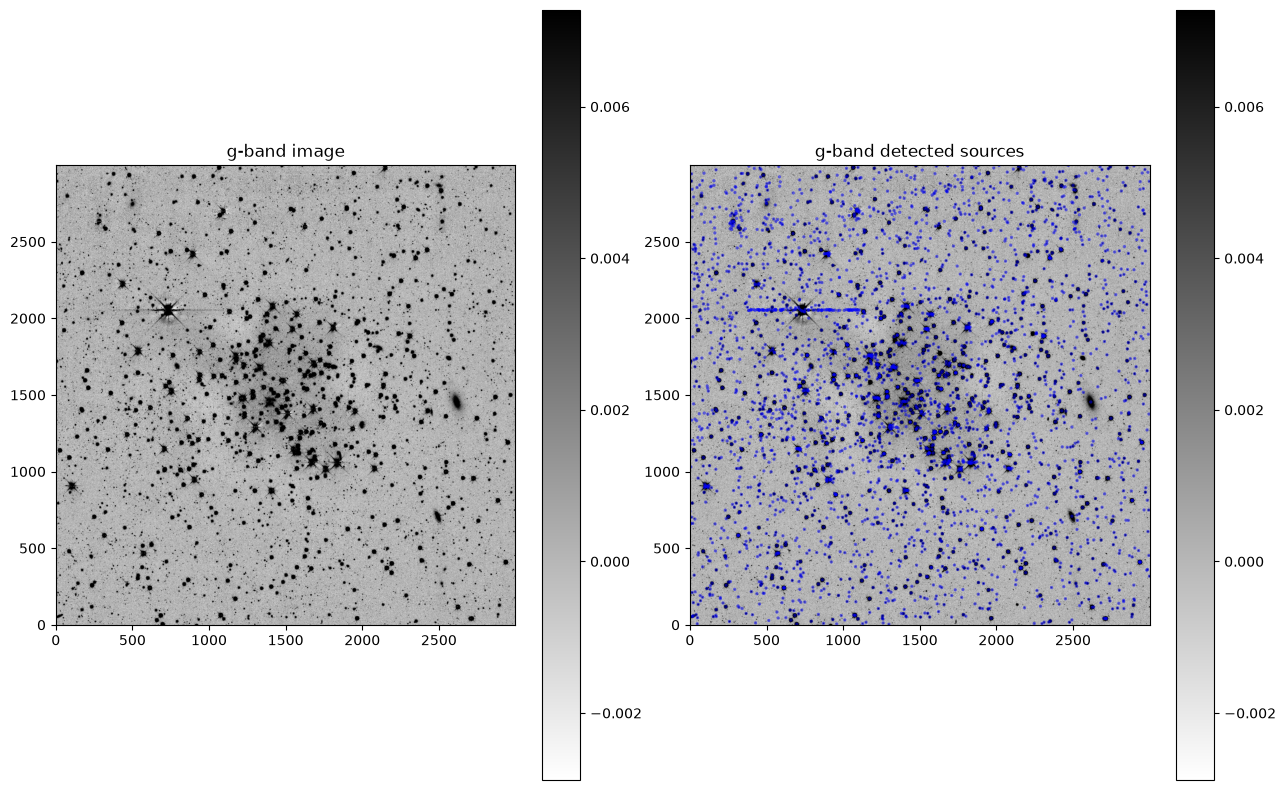

In [51]:
# set up daofind, with info about our image fwhm and the detection threshold
#*****************************************
daofind = DAOStarFinder(fwhm=fwhm_g, threshold=5.5*std_g) #Originally tried 4 but increased after plotting sigma to detection

# detect sources, using the image - median, which subtracts the sky level from the image, 
# assuming a sky that is constant across the image
sources_g = daofind(data_g - median_g)

# convert pixel locations of the sources to ra and dec using the image WCS
wcs_g = WCS(header_g)
ra_g,dec_g = wcs_g.wcs_pix2world(sources_g['xcentroid'],sources_g['ycentroid'],0)

# plot images and the sources.  using the subplot command we can plot figures side by side
plt.figure(figsize=(15,10))
# select the left plot
plt.subplot(1,2,1)
imdisplay(data_g)
plt.title('g-band image')

# plot g-band image with the positions of the sources overlaid
# select the right plot
plt.subplot(1,2,2)

# Create a list of positions of all the stars, as determined by the DAOStarFinder above.  
# The transpose command puts the positions into the correct format
positions = np.transpose((sources_g['xcentroid'], sources_g['ycentroid']))
# creates a set of circular apertures (r=6 pixels = 3 arcsec; smaller than the lab since this field is crowded)
apertures = CircularAperture(positions, r=6.)
imdisplay(data_g)
# plot the apertures. the ';' at the end suppresses some messy output
apertures.plot(color='blue', lw=1.0, alpha=0.5);
plt.title('g-band detected sources')

Plot shows detected sources from g-band with selected sigma. Can also see that a saturation artifact was detected.

Text(0.5, 1.0, 'g-band')

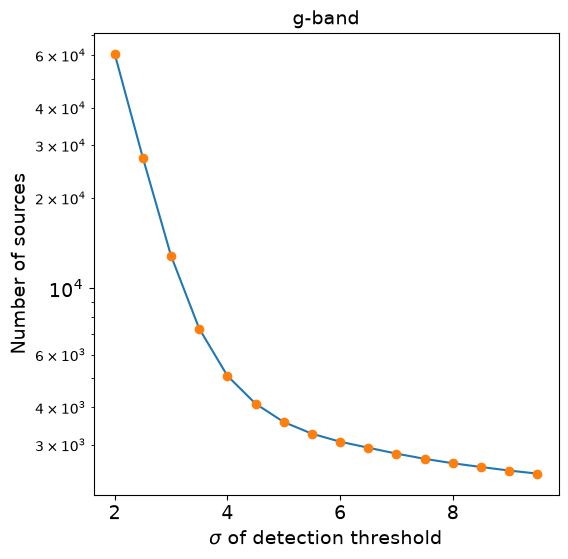

In [52]:
# This makes a plot of the number of sources for different detection thresholds for the g-band
# set up an array of thresholds
thresharr = np.arange(2.,10.,0.5)

# initialize an array that will hold the number of sources detected at each threshold
nsources_g = np.zeros(len(thresharr))

# loop through the thresholds to find how many sources are detected at each threshold
for ithresh,thresh in enumerate(thresharr):
    daofind_tmp = DAOStarFinder(fwhm=fwhm_g, threshold=thresh*std_g)
    sources_gtmp = daofind_tmp(data_g - median_g)
    nsources_g[ithresh] = len(sources_gtmp)

# plot the number of sources at each threshold
fig,ax = plt.subplots(figsize=(6,6))
ax.plot(thresharr,nsources_g)
ax.plot(thresharr,nsources_g, 'o')
ax.set_yscale('log')
ax.set_ylabel('Number of sources', fontsize=14)
ax.set_xlabel(r'$\sigma$ of detection threshold', fontsize=14)
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)
ax.set_title('g-band', fontsize=14)

Switched from sigma=4 to 5.5 because of plots, closer to plateua start. The plot shows how many sources are detected based on a chosen sigma value.

Text(0.5, 1.0, 'r-band detected sources')

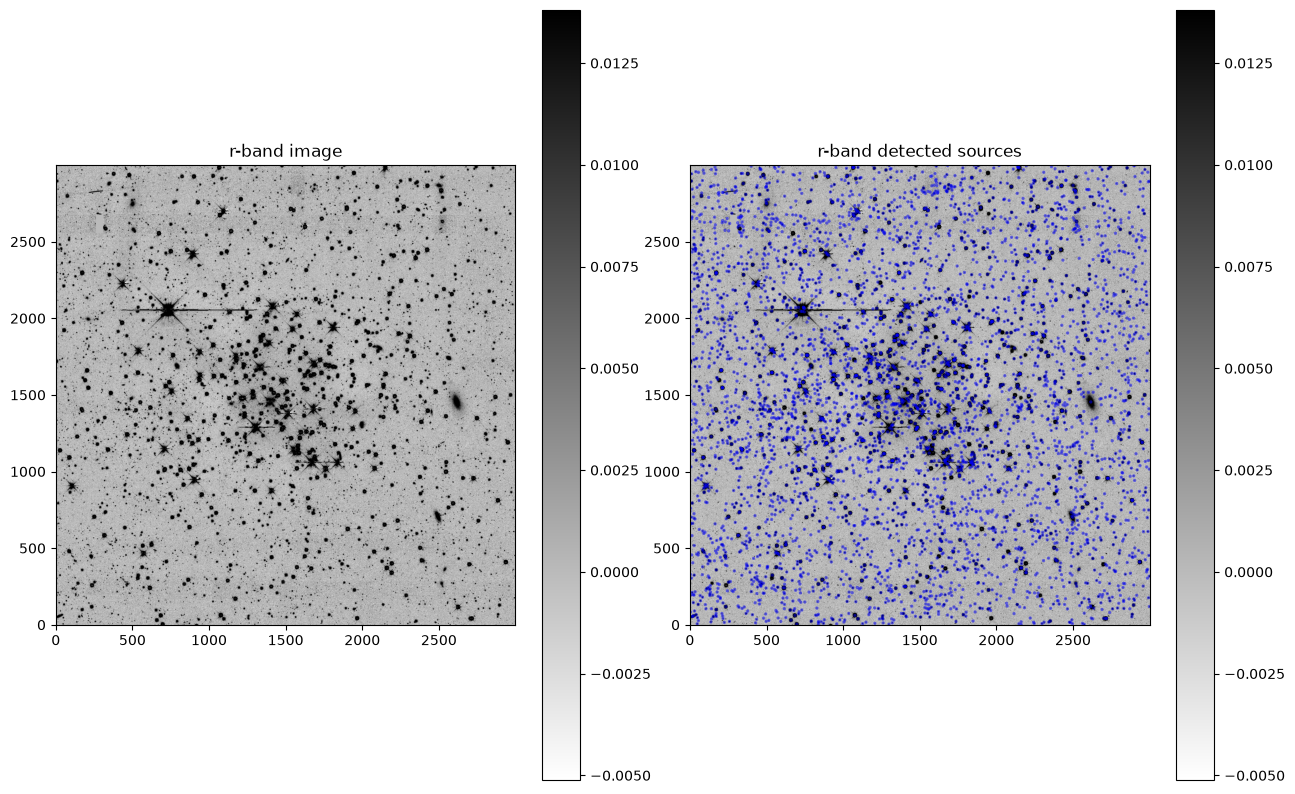

In [53]:
#repeat stuff for r
# read in the r-band image
data_r, header_r = fits.getdata('M67r.fits',header=True)
# estimate the background counts in the image by computing the 
# mean and median excluding all pixels greater than 3-sigma above the mean
mean_r, median_r, std_r = sigma_clipped_stats(data_r, sigma=3.0)


# set up daofind, with info about our image fwhm and the detection threshold
#*****************************************
daofind = DAOStarFinder(fwhm=fwhm_r, threshold=5.5*std_r) #was 4, switched to 5.5 to optimize detection from graph of next code cell.

# detect sources, using the image - median, which subtracts the sky level from the image, 
# assuming a sky that is constant across the image
sources_r = daofind(data_r - median_r)

# convert pixel locations of the sources to ra and dec using the image WCS
wcs_r = WCS(header_g)
ra_r,dec_r = wcs_r.wcs_pix2world(sources_r['xcentroid'],sources_r['ycentroid'],0)

# plot images and the sources.  using the subplot command we can plot figures side by side
plt.figure(figsize=(15,10))
# select the left plot
plt.subplot(1,2,1)
imdisplay(data_r)
plt.title('r-band image')

# plot r-band image with the positions of the sources overlaid
# select the right plot
plt.subplot(1,2,2)

# Create a list of positions of all the stars, as determined by the DAOStarFinder above.  
# The transpose command puts the positions into the correct format
positions = np.transpose((sources_r['xcentroid'], sources_r['ycentroid']))
# creates a set of circular apertures (r=6 pixels = 3 arcsec; smaller than the lab since this field is crowded)
apertures = CircularAperture(positions, r=6.)
imdisplay(data_r)
# plot the apertures. the ';' at the end suppresses some messy output
apertures.plot(color='blue', lw=1.0, alpha=0.5);
plt.title('r-band detected sources')

repeat of above for r band, detected sources. Did not detect that saturation artifact this time.

Text(0.5, 1.0, 'r-band')

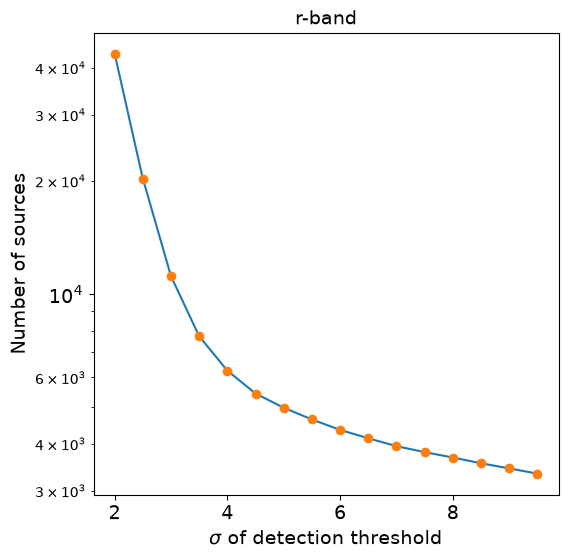

In [54]:


# repeat for the r-band image
data_r, header_r = fits.getdata('M67r.fits',header=True)

mean_r, median_r, std_r = sigma_clipped_stats(data_r, sigma=3.0)

# set up an array of thresholds
thresharr = np.arange(2.,10.,0.5)

# initialize an array that will hold the number of sources that are detected at each threshold
nsources_r = np.zeros(len(thresharr))

# loop through the thresholds to find how many sources are detected at each threshold
for ithresh,thresh in enumerate(thresharr):
    daofind_tmp = DAOStarFinder(fwhm=fwhm_r, threshold=thresh*std_r)
    sources_rtmp = daofind_tmp(data_r - median_r)
    nsources_r[ithresh] = len(sources_rtmp)

# plot the number of sources at each threshold
fig,ax = plt.subplots(figsize=(6,6))
ax.plot(thresharr,nsources_r)
ax.plot(thresharr,nsources_r, 'o')
ax.set_yscale('log')
ax.set_ylabel('Number of sources', fontsize=14)
ax.set_xlabel(r'$\sigma$ of detection threshold', fontsize=14)
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)
ax.set_title('r-band', fontsize=14)

same as g's but in r. Sigma that gets you a # of detected sources


In [55]:
print('g sources:', len(sources_g))
print('r sources:', len(sources_r))

g sources: 3264
r sources: 4640


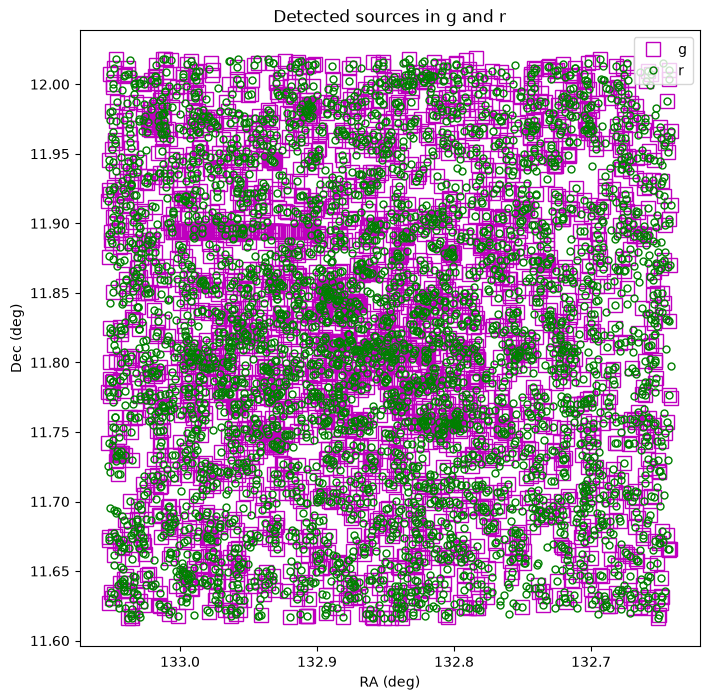

In [56]:
#************************* took this from labs
# make a plot of the RA and DEC of the sources in the g and r images

# boolean flags for good positions (> 50 pixels from every edge) in the g and r-band images
ny, nx = data_g.shape
noedgeflag_g = ((sources_g['xcentroid'] > 50) & (sources_g['xcentroid'] < nx-50) &
                (sources_g['ycentroid'] > 50) & (sources_g['ycentroid'] < ny-50))
noedgeflag_r = ((sources_r['xcentroid'] > 50) & (sources_r['xcentroid'] < nx-50) &
                (sources_r['ycentroid'] > 50) & (sources_r['ycentroid'] < ny-50))

# open a figure
plt.figure(figsize=(8,8))

# plot the positions of the g sources
plt.plot(ra_g[noedgeflag_g], dec_g[noedgeflag_g],'ms',mfc='None',markersize=10,label='g')

# plot the positions of the r sources
plt.plot(ra_r[noedgeflag_r], dec_r[noedgeflag_r],'g.',mfc='None',markersize=10,label='r')

# add a legend
plt.legend()

# label your axes
plt.xlabel('RA (deg)')
plt.ylabel('Dec (deg)')
plt.gca().invert_xaxis()   # RA increases to the left on the sky
plt.title('Detected sources in g and r')

# save your plot
plt.savefig('M67_g_r_positions.png')

Can see a lot of places that match and a lot of places that don't. Also can see that some saturation is picked up by g, while r might pick up the same star several times. The plot shows where sources were detected in g and r and relies on human eyes to compare, but next cell gives numbers.

In [57]:
# this creates a SkyCoord object containing the g and r catalogs
g_catalog = SkyCoord(ra=ra_g*u.degree, dec=dec_g*u.degree)
r_catalog = SkyCoord(ra=ra_r*u.degree, dec=dec_r*u.degree)

# this matches the two catalogs and outputs an array of indices, idx, that when passed to r_catalog
# gives the ids of the matched sources for each source in g_catalog.
idx, d2d, d3d = g_catalog.match_to_catalog_sky(r_catalog)

# we are going to keep matches that have offsets less than 1 arcsecond
# (tighter than the lab's 2" because this is a crowded cluster field with 0.5"/pixel images,
#  so a larger radius would risk matching the wrong star)
matchflag = d2d < 1./3600*u.deg
gmag = sources_g['mag'][matchflag]
rmag = sources_r['mag'][idx[matchflag]]

# also keep the sky position of each matched star (taken from the g catalog) for the radial analysis later
ra_match  = ra_g[matchflag]
dec_match = dec_g[matchflag]

print('number of matched stars:', matchflag.sum())
print(gmag, rmag)

number of matched stars: 2709
    mag    
-----------
  -7.130207
0.008810542
 0.09420843
  2.3969915
 0.36534816
-0.70500994
  1.2843578
  1.7311406
  1.5334628
  1.0965497
        ...
   1.678986
 0.41554666
  1.8482242
  0.7915068
  1.5110618
-0.45747054
 -2.6530914
 -0.3872332
 -0.5411042
 -4.1852064
Length = 2709 rows     mag     
------------
   -5.513718
 -0.49214923
  -1.3878714
    0.683207
  -1.2366698
  -2.2004964
  -0.5983215
  0.16157575
  0.04871519
 -0.41258442
         ...
   1.0179029
  -1.3237661
  0.61233884
-0.034665134
   1.1199707
  -1.8099761
  -3.5017278
  -1.7443252
  -1.4517918
  -4.8406534
Length = 2709 rows


In [58]:
#***********************
# convert instrumental magnitudes in each band to calibrated magnitudes.
zp_g = float(header_g['PHOTZP'])
zp_r = float(header_r['PHOTZP'])

gmag_cal = gmag + zp_g
rmag_cal = rmag + zp_r

print(gmag_cal)
print(rmag_cal)

   mag   
---------
15.369793
 22.50881
22.594208
24.896992
22.865349
 21.79499
23.784357
 24.23114
24.033463
 23.59655
      ...
24.178986
22.915546
24.348225
23.291508
24.011063
 22.04253
19.846909
22.112766
21.958897
18.314793
Length = 2709 rows
   mag   
---------
16.986282
 22.00785
 21.11213
23.183207
 21.26333
20.299503
21.901678
22.661575
22.548716
22.087416
      ...
23.517902
21.176233
23.112339
22.465334
 23.61997
20.690023
18.998272
20.755674
21.048208
17.659348
Length = 2709 rows


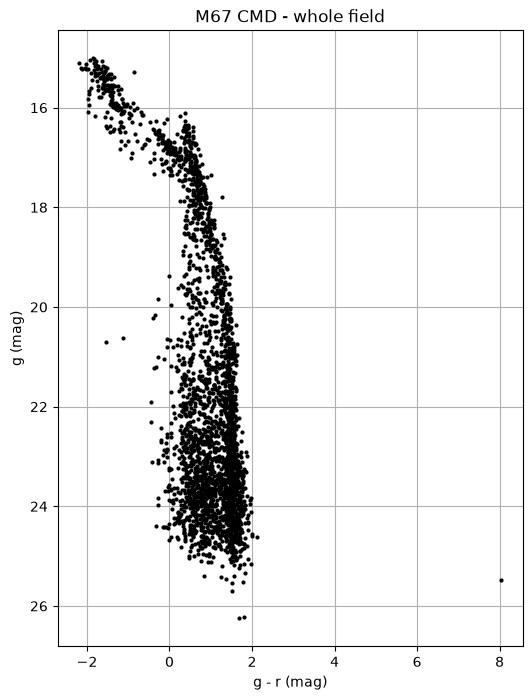

In [59]:
#**************************
# CMD: g magnitude vs g - r color (lab used B-V)
plt.figure(figsize=(6,8))
plt.plot(gmag_cal - rmag_cal, gmag_cal, 'k.', markersize=4)
plt.xlabel('g - r (mag)')
plt.ylabel('g (mag)')
plt.title('M67 CMD - whole field')

plt.gca().invert_yaxis()   # brighter stars (smaller magnitudes) at the top
plt.grid(True)
plt.savefig('M67_CMD_all.png')

This is not what I wanted to see. There is a leftwards turn-off, but no observable giant branch. My theory is that M67 is too close and the legacy survey saturates the close giants too easily. Therefore, all the brightest stars (giants) saturated and don't have reliable g-r numbers. Plot shows color of stars vs their magnitude in g. The data point at g-r=8 is certainly not real and messes with the scale a bit.

In [60]:
#Cut out the inside of the cluster
#For this I drew a circle in DS9 to exclude the most populated area around the center
circle_center = SkyCoord('08h51m22.6297s', '+11d49m38.029s')   # RA in hours, as ds9 shows it
circle_radius = 0.1043291 * u.deg                              # = 6.26 arcmin

coords_g = SkyCoord(ra_g*u.deg, dec_g*u.deg)
outer_g = coords_g.separation(circle_center) > circle_radius #separation computes great circle distance,
#Check if the separation is larger than the circle radius (outside circle), add to outer_g
sources_g_outer = sources_g[outer_g]
print(f'g: {outer_g.sum()} of {len(sources_g)} outside the circle')

coords_r = SkyCoord(ra_r*u.deg, dec_r*u.deg)
outer_r = coords_r.separation(circle_center) > circle_radius
sources_r_outer = sources_r[outer_r]
print(f'r: {outer_r.sum()} of {len(sources_r)} outside the circle')

g: 2286 of 3264 outside the circle
r: 3451 of 4640 outside the circle


1992 of 2709 matched stars are outside the circle


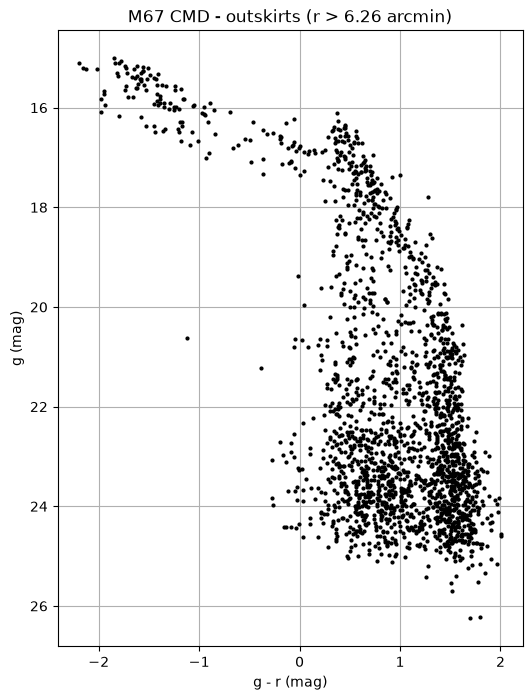

In [64]:
#get color into a variable to use later
color = gmag_cal - rmag_cal

#get coords of matched stars
coords_cmd = SkyCoord(ra=ra_match*u.deg, dec=dec_match*u.deg)

outskirts_stars = coords_cmd.separation(circle_center) > circle_radius #outskirts stars are outside circle
print(f'{outskirts_stars.sum()} of {len(color)} matched stars are outside the circle') 

plt.figure(figsize=(6,8))
plt.plot(color[outskirts_stars], gmag_cal[outskirts_stars], 'k.', markersize=4)
plt.xlabel('g - r (mag)')
plt.ylabel('g (mag)')
plt.title(f'M67 CMD - outskirts (r > {circle_radius.to(u.arcmin):.2f})')
#plot title has radius from center and number reported
plt.gca().invert_yaxis()
plt.grid(True)
plt.savefig('M67_CMD_outskirts.png')

Another CMD is above only including outskirts sources. that g-r=8 source is not here so it must have been inside the center area. I am wondering if it was a saturation artifact because in the band images you can see the most saturates star on the image has the saturation line different lengths depending on the band it was taken in. Though, the star catalogue matching would have to fail somehow to get that into this data. The giant branch is still missing probably still because of saturation issues.

In [62]:
"""
Store the M67 data to plot together with M5
"""
# Stash the M67 outskirts CMD
M67_cmd_color = np.array(color[outskirts_stars])
M67_cmd_g = np.array(gmag_cal[outskirts_stars])

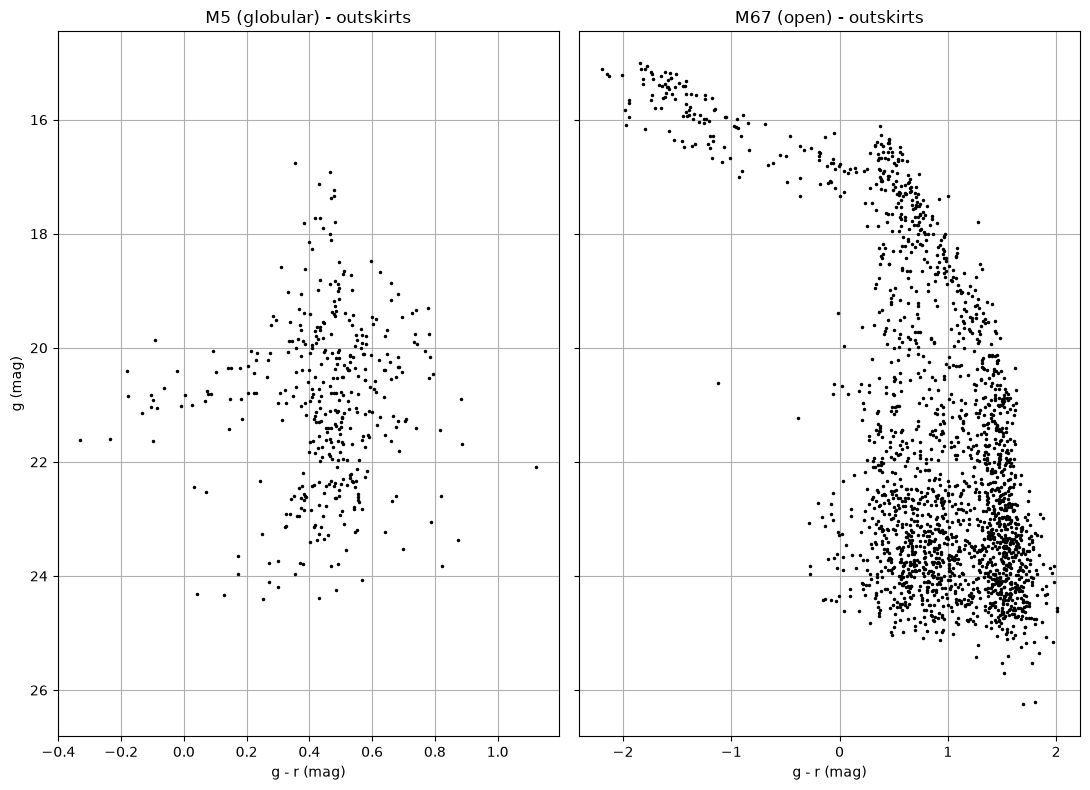

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 8), sharey=True) #Share y axis for comparison

axes[0].plot(M5_cmd_color, M5_cmd_g, 'k.', markersize=3)
axes[0].set_title(f'M5 (globular) - outskirts')

axes[1].plot(M67_cmd_color, M67_cmd_g, 'k.', markersize=3)
axes[1].set_title(f'M67 (open) - outskirts')

for ax in axes:
    ax.set_xlabel('g - r (mag)')
    ax.grid(True)
axes[0].set_ylabel('g (mag)')
axes[0].invert_yaxis()   # sharey, so this flips both panels

plt.tight_layout()
plt.savefig('CMD_outskirts_comparison.png')
plt.show()

The above plots are both CMDs. M5 is on the left and M67 on the right. Neither have a good visible giant branch though M67 looks to have a visible turnoff. We suspect this to be due to the nature of DR11 and how bright giants get at the exposure depth done for the survey. We think the giants saturated and therefore have bad color data.

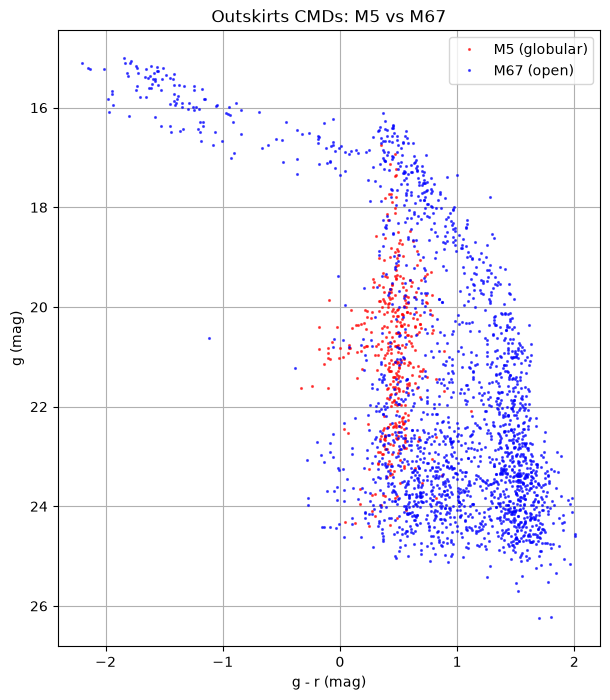

In [ ]:
plt.figure(figsize=(7, 8))

plt.plot(M5_cmd_color, M5_cmd_g, 'r.', markersize=2.5, alpha=0.6, label='M5 (globular)')
plt.plot(M67_cmd_color, M67_cmd_g, 'b.', markersize=2.5, alpha=0.6, label='M67 (open)')

plt.xlabel('g - r (mag)')
plt.ylabel('g (mag)')
plt.title('Outskirts CMDs: M5 vs M67')
plt.gca().invert_yaxis()
plt.legend()
plt.grid(True)
plt.savefig('CMD_outskirts_overlay.png', dpi=150)
plt.show()

The above plot overlays the two CMDs on each other. From this, it can be seen that on average the plotted stars in M5 are bluer (lower g-r) than those in M67. The M5 stars sit in a narrow column around g-r ≈ 0.5, while the stars in M67 stars spread over a much wider range of colors, mostly higher g-r except for when g<18. M67 stars get out to out to g-r ≈ 1.5–2 at faint magnitudes. Fewer M5 stars are plotted overall. We believe M5 is seen as bluer on average because it is further away, and the dimmer, redder stars might not be imaged as easily as in M67. Upon being able to reflect and looking at both graphs at the same time, we believe M67 does have a giant branch but the stars are saturated and appear to the left since their full magnitudes couldn't be captured. Our detection limit theory on the M5 stars is supported by the amount of stars with lower g magnitudes that are visible in the M67 plotted values.